Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Member 2 — Statistical Summary & Data Distributions

In [4]:

athletes = pd.read_csv(r"../data/raw/athlete_events.csv")
regions = pd.read_csv(r"../data/raw/noc_regions.csv")
df = athletes.merge(regions, on="NOC", how="left")

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,271116.0,68248.954396,39022.286345,1.0,34643.0,68205.0,102097.25,135571.0
Age,261642.0,25.556898,6.393561,10.0,21.0,24.0,28.00,97.0
Height,210945.0,175.338970,10.518462,127.0,168.0,175.0,183.00,226.0
Weight,208241.0,70.702393,14.348020,25.0,60.0,70.0,79.00,214.0
Year,271116.0,1978.378480,29.877632,1896.0,1960.0,1988.0,2002.00,2016.0


In [13]:
#Investigate the categorical features.
categorical_cols = df.select_dtypes(include=['object', 'str']).columns

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print("Unique values:", df[col].nunique())
    print(df[col].value_counts().head(10))


--- Name ---
Unique values: 134732
Name
Robert Tait McKenzie                58
Heikki Ilmari Savolainen            39
Joseph "Josy" Stoffel               38
Ioannis Theofilakis                 36
Takashi Ono                         33
Alfrd (Arnold-) Hajs (Guttmann-)    32
Jean Lucien Nicolas Jacoby          32
Alexandros Theofilakis              32
Andreas Wecker                      32
Alfred August "Al" Jochim           31
Name: count, dtype: int64

--- Sex ---
Unique values: 2
Sex
M    196594
F     74522
Name: count, dtype: int64

--- Team ---
Unique values: 1184
Team
United States    17847
France           11988
Great Britain    11404
Italy            10260
Germany           9326
Canada            9279
Japan             8289
Sweden            8052
Australia         7513
Hungary           6547
Name: count, dtype: int64

--- NOC ---
Unique values: 230
NOC
USA    18853
FRA    12758
GBR    12256
ITA    10715
GER     9830
CAN     9733
JPN     8444
SWE     8339
AUS     7638
HUN     660

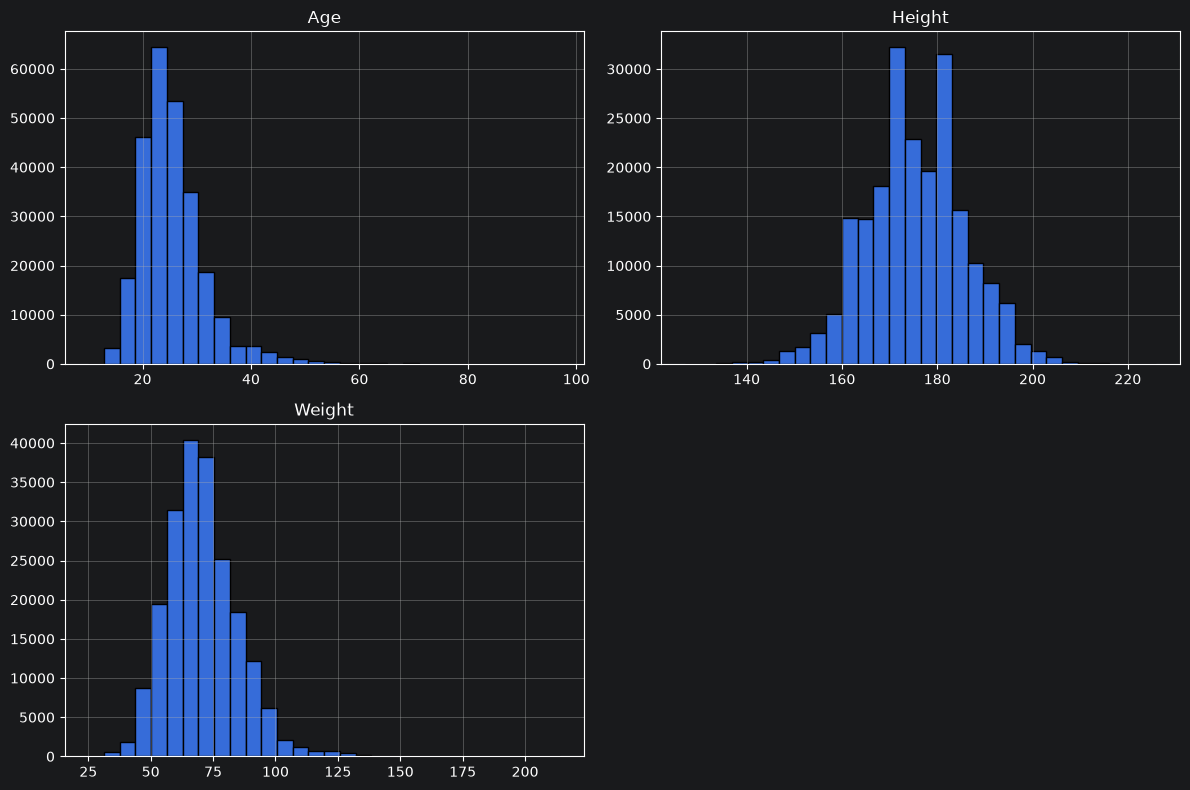

In [11]:
#Understand athlete distributions
numerical_features = ['Age', 'Height', 'Weight']

df[numerical_features].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor='black'
)

plt.tight_layout()
plt.show()

The three numerical features have different distribution patterns. Age and weight show positive skewness, while height is more concentrated around its central range with multiple peaks. The presence of extreme values suggests that further investigation of potential outliers may be useful during the data-cleaning and exploratory data analysis stages.

In [12]:
# understand gender distribution
print(df['Sex'].value_counts())
print("\nPercentage distribution:")
print(df['Sex'].value_counts(normalize=True) * 100)

Sex
M    196594
F     74522
Name: count, dtype: int64

Percentage distribution:
Sex
M    72.512873
F    27.487127
Name: proportion, dtype: float64


### Initial Observations

1. **Athlete Names:** The dataset contains 134,732 unique athlete names, indicating a large number of individual participants. Some names appear multiple times because an athlete may participate in several events or Olympic editions.

2. **Gender Distribution:** The dataset contains two gender categories (M and F). Male athlete records (196,594) are considerably more frequent than female records (74,522), suggesting an imbalance in gender representation across the recorded Olympic events.

3. **Teams and Countries:** There are 1,184 unique team names and 230 NOC codes. The United States has the highest number of athlete records (17,847 by team name), followed by France and Great Britain.

4. **Olympic Games:** The dataset covers 51 Olympic editions. The 2000 Summer Olympics has the highest number of athlete records (13,821), followed closely by the 1996 and 2016 editions.

5. **Seasons:** Summer Olympics account for 222,552 records, compared with 48,564 for Winter Olympics. This indicates that Summer Games are more heavily represented in the dataset.

6. **Host Cities:** There are 42 unique host cities. London appears most frequently (22,426 records), followed by Athens (15,556) and Sydney (13,821).

7. **Sports and Events:** The dataset covers 66 sports and 765 events. Athletics has the highest number of records (38,624), followed by Gymnastics and Swimming. Football is the most frequently recorded event.

8. **Medals:** Three medal categories are present: Gold, Silver, and Bronze. Their frequencies are relatively close, with Gold appearing most frequently (13,372 records).

9. **Regions and Historical Teams:** The merged dataset contains 205 unique regions and 21 distinct notes. The notes column includes historical country names and special team classifications, highlighting the complexity of representing countries consistently across different Olympic periods.

### General Observation

The categorical analysis shows that the dataset covers a wide range of Olympic participants, countries, sports, events, and historical editions. However, the frequencies represent athlete-event records rather than necessarily unique athletes, teams, or medals. Therefore, unique identifiers and appropriate grouping should be considered in subsequent analyses.